# CascadeLUT Demo — MNIST

Demonstrates the full cascade pipeline:
1. **Phase 1** — dense training with full input to learn feature importance ordering
2. **Phase 2** — cascade dense training to learn sparse connectivity masks
3. **Phase 3** — sparse incremental training with learned masks
4. **neq2lut** — convert NEQs to LUT truth tables
5. **Verilog** — generate synthesisable cascade RTL

Epoch counts are reduced from the paper run so the notebook completes quickly.

In [2]:
import sys, os, types

import cascadelut
import cascadelut.nn
import cascadelut.quant
import cascadelut.synthesis

import wandb
wandb.init(mode='disabled')  # suppress wandb calls inside train.py

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from cascadelut.nn import generate_truth_tables, lut_inference, module_list_to_verilog_module
from models import MnistCascadeModel, _parse_cascade_chunks
import train as _train

## Config

Smaller architecture to train faster, but same cascade structure as the paper.

In [ ]:
CUDA = torch.cuda.is_available()
print(f'CUDA: {CUDA}')

demo_cfg = {
    'hidden_layers':  [2160, 360, 2160, 360, 60],
    'support_layers': [0, 1, 0, 1, 1, 1],
    'cascade_layers': [1, 0, 2, 0, 0],
    'input_bitwidth':   1, 'hidden_bitwidth':  1,
    'output_bitwidth':  6, 'support_bitwidth': 1,
    'input_fanin':   6, 'hidden_fanin':   6,
    'output_fanin':  6, 'support_fanin':  6,
    'cascade_fanin': 8, 'width_n': 16, # reduced for demo
    'batch_size': 64, 'learning_rate': 0.0016,
    'weight_decay': 0.0002, 'label_smoothing': 0.05,
    'input_dropout': 0.08, 'features_per_cycle': 112,
    'dense1_epochs': 3, 'dense2_epochs': 8, 'epochs': 20, # reduced for demo
    'warmup_epochs': 2,
    'wd': 0.00012, 'wd1': 0.03,
    'start_temp': 1.8, 'end_temp': 0.02,
    'anneal_epochs': 20, 'use_anneal': True,
    'threshold_reg_strength': 0.000005,
    'threshold_reg_noise_std': 0.0,
    'seed': 42, 'cuda': CUDA,
    'input_length': 784, 'output_length': 10,
}

CUDA: True


## MNIST dataset

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])
train_loader = DataLoader(
    datasets.MNIST('mnist_data', download=True, train=True,  transform=transform),
    batch_size=demo_cfg['batch_size'], shuffle=True,
)
test_loader = DataLoader(
    datasets.MNIST('mnist_data', download=True, train=False, transform=transform),
    batch_size=demo_cfg['batch_size'], shuffle=False,
)

In [6]:
def eval_model(model, loader, cuda=True):
    """Run test-set evaluation without touching wandb or global state."""
    model.eval()
    correct = 0
    with torch.no_grad():
        for data, target in loader:
            if cuda:
                data, target = data.cuda(), target.cuda()
            correct += model(data.reshape(-1, 784)).argmax(1).eq(target).sum()
    return 100.0 * correct / len(loader.dataset)

## Phase 1: Dense training with full input

The model sees the complete 784-pixel image at every cascade layer (`full_input_mode=True`). After training, we rank input features by their weight magnitudes to determine the per-chunk importance ordering.

In [7]:
import random
seed = demo_cfg['seed']
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
if CUDA:
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

model_cfg = dict(demo_cfg)
model_cfg['dense_forward']   = True
model_cfg['full_input_mode'] = True
model_cfg['imask']           = torch.tensor([]).cuda() if CUDA else torch.tensor([])
model_cfg['importance_order']= torch.arange(784, dtype=torch.long)

train_cfg = {k: demo_cfg[k] for k in _train.training_config if k in demo_cfg}
opts      = {'cuda': CUDA, 'log_dir': 'cascade_demo', 'checkpoint': None, 'device': 0}

os.makedirs('test_cascade_demo', exist_ok=True)

_train.model_cfg = model_cfg
_train.train_cfg = train_cfg

model_phase1 = MnistCascadeModel(model_cfg)
if CUDA:
    model_phase1.cuda()

print('=== Phase 1: Dense (full-input) ===')
_train.train(model_phase1, train_cfg, opts)

=== Phase 1: Dense (full-input) ===


/home/ojc23/.conda/envs/assemble/lib/python3.8/site-packages/torch/_tensor.py:1413: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at ../c10/core/TensorImpl.h:1925.)
  return super().rename(names)


Epoch: 0/3	Test Acc: 89.36
Epoch: 1/3	Test Acc: 93.77
Epoch: 2/3	Test Acc: 94.66


## Compute importance ordering

Rank the 784 input features by how heavily each dense layer weights them, then partition into non-overlapping chunks of `features_per_cycle` features.

In [8]:
model_phase1.eval()
importance_order = _train.calculate_cascade_importance_order_frequency(
    model_phase1, model_cfg, CUDA
)
print(f'Importance order shape: {importance_order.shape}')

B = demo_cfg['features_per_cycle']
for c in range(2):
    seg = importance_order[c * B : (c + 1) * B].tolist()
    print(f'  Chunk {c}: top-5 feature indices = {seg[:5]} ...')

torch.save(importance_order, 'test_cascade_demo/importance_order.pth')

# Update config for subsequent phases
model_cfg['importance_order'] = importance_order
model_cfg['full_input_mode']  = False
_train.model_cfg = model_cfg

del model_phase1
if CUDA:
    torch.cuda.empty_cache()

Importance order shape: torch.Size([784])
  Chunk 0: top-5 feature indices = [294, 266, 293, 350, 321] ...
  Chunk 1: top-5 feature indices = [434, 407, 491, 437, 433] ...


## Feature loading order

Each pixel is coloured by the cascade cycle in which it is loaded — 
first two cycles highlighted, the remainder in grayscale.

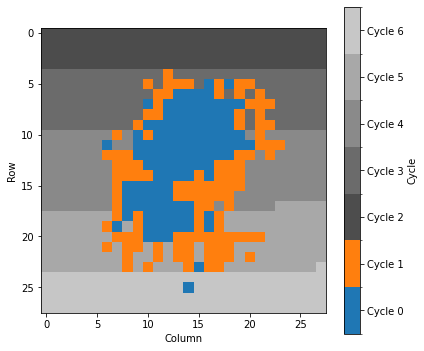

In [9]:
B     = demo_cfg['features_per_cycle']
io_np = importance_order.cpu().numpy()
N     = len(io_np)
n_cyc = int(np.ceil(N / B))

grid = np.empty(N, dtype=int)
for c in range(n_cyc):
    for idx in range(c * B, min((c + 1) * B, N)):
        grid[io_np[idx]] = c
grid_2d = grid.reshape(28, 28)

show_n  = 2
tab10   = plt.cm.tab10(np.linspace(0, 1, 10))
colours = []
for c in range(n_cyc):
    if c < show_n:
        colours.append(tab10[c % 10])
    else:
        g = 0.3 + 0.6 * (c - show_n) / max(1, n_cyc - show_n)
        colours.append([g, g, g, 1.0])

cmap = mcolors.ListedColormap(colours)
norm = mcolors.BoundaryNorm(np.arange(-0.5, n_cyc + 0.5), cmap.N)

fig, ax = plt.subplots(figsize=(6, 6))
im      = ax.imshow(grid_2d, cmap=cmap, norm=norm, interpolation='nearest')

cbar = fig.colorbar(im, ax=ax, ticks=range(n_cyc), shrink=0.8)
cbar.set_label('Cycle')
cbar.ax.set_yticklabels([f'Cycle {c}' for c in range(n_cyc)])

ax.set_xlabel('Column')
ax.set_ylabel('Row')
plt.tight_layout()
plt.show()

## Phase 2: Cascade dense training → sparse mask

Train the cascade architecture in dense mode with chunks arriving following the importance order. After training, we extract `imask`: the learned sparse connectivity for each neuron.

In [10]:
model_cfg['dense_forward'] = True
_train.model_cfg = model_cfg

model_phase2 = MnistCascadeModel(model_cfg)
if CUDA:
    model_phase2.cuda()

print('=== Phase 2: Cascade dense ===')
_train.train(model_phase2, train_cfg, opts)

imask = _train.GetInputMask(model_phase2, CUDA)
print(f'Extracted imask: {imask.shape}')
torch.save(imask, 'test_cascade_demo/imask_cascade.pth')

del model_phase2
if CUDA:
    torch.cuda.empty_cache()

=== Phase 2: Cascade dense ===
Epoch: 0/8	Test Acc: 92.31
Epoch: 1/8	Test Acc: 94.14
Epoch: 2/8	Test Acc: 94.93
Epoch: 3/8	Test Acc: 95.33
Epoch: 4/8	Test Acc: 95.71
Epoch: 5/8	Test Acc: 95.73
Epoch: 6/8	Test Acc: 95.84
Epoch: 7/8	Test Acc: 96.10
Extracted imask: torch.Size([4320, 8])


## Phase 3: Sparse incremental training

Now train with the learned `imask` and real chunked input loading. Each cascade layer only receives the features its neurons were connected to during the dense phase.

In [11]:
model_cfg['dense_forward'] = False
model_cfg['imask']         = imask.cuda() if CUDA else imask
_train.model_cfg = model_cfg

model = MnistCascadeModel(model_cfg)
if CUDA:
    model.cuda()

print('=== Phase 3: Sparse incremental ===')
_train.train(model, train_cfg, opts)
print(f'Final test accuracy: {eval_model(model, test_loader, CUDA):.2f}%')

=== Phase 3: Sparse incremental ===
Final test accuracy: 95.62%


## NEQ → LUT conversion

Calculate the Boolean truth table for every neuron, then switch the model to LUT-based forward inference.

In [12]:
print('Converting NEQs to LUTs...')
generate_truth_tables(model, verbose=True)
lut_inference(model)
print(f'LUT model accuracy: {eval_model(model, test_loader, CUDA):.2f}%')

Converting NEQs to LUTs...
Fixed input_quant for layer 5 from previous layer's output_quant
Patched cascade layer module_list.2
Calculating truth tables for module_list.0
Truth tables generated for 2160 neurons
Calculating truth tables for module_list.1
Truth tables generated for 360 neurons
Calculating truth tables for module_list.2
Truth tables generated for 2160 neurons
Calculating truth tables for module_list.3
Truth tables generated for 360 neurons
Calculating truth tables for module_list.4
Truth tables generated for 60 neurons
Calculating truth tables for module_list.5
Truth tables generated for 10 neurons
LUT model accuracy: 95.63%


## Verilog generation

Generate per-layer Verilog modules and the cascade top-level that wires them together with pipeline registers and chunk-loading control logic.

In [13]:
verilog_dir = 'test_cascade_demo/verilog'
os.makedirs(verilog_dir, exist_ok=True)

cascade_chunks = _parse_cascade_chunks(demo_cfg['cascade_layers'])

module_list_to_verilog_module(
    model.module_list,
    'cascade_demo',
    verilog_dir,
    add_registers=True,
    cascade_config={
        'enabled':        True,
        'features_per_cycle': demo_cfg['features_per_cycle'],
        'cascade_chunks': cascade_chunks,
        'cascade_layers': demo_cfg['cascade_layers'],
    },
)
print(f'Verilog written to: {verilog_dir}/cascade_demo.v')
print(f'Layer files: {[f for f in os.listdir(verilog_dir) if f.endswith(".v")]}')

Generated cascade top module: test_cascade_demo/verilog/cascade_demo.v
Verilog written to: test_cascade_demo/verilog/cascade_demo.v
Layer files: ['layer2_N509.v', 'layer2_N442.v', 'layer3_N186.v', 'layer0_N1200.v', 'layer2_N914.v', 'layer0_N654.v', 'layer2_N1096.v', 'layer2_N1475.v', 'layer2_N1923.v', 'layer2_N1868.v', 'layer2_N1566.v', 'layer2_N1830.v', 'layer0_N1313.v', 'layer3_N26.v', 'layer2_N37.v', 'layer0_N1258.v', 'layer2_N551.v', 'layer0_N15.v', 'layer2_N1185.v', 'layer1_N283.v', 'layer4_N51.v', 'layer0_N747.v', 'layer2_N807.v', 'layer2_N394.v', 'layer0_N182.v', 'layer0_N1880.v', 'layer2_N1740.v', 'layer0_N561.v', 'layer0_N837.v', 'layer2_N777.v', 'layer0_N1135.v', 'layer0_N539.v', 'layer0_N472.v', 'layer0_N1026.v', 'layer2_N2076.v', 'layer2_N664.v', 'layer0_N924.v', 'layer2_N287.v', 'layer2_N1653.v', 'layer2_N1718.v', 'layer0_N1993.v', 'layer0_N1579.v', 'layer0_N1432.v', 'layer2_N270.v', 'layer0_N1964.v', 'layer1_N141.v', 'layer2_N1247.v', 'layer0_N485.v', 'layer3_N357.v', 'la